# ANN — Binary Classification on `make_moons`

**Kernel:** Python (ML .venv)

```powershell
cd Machine-Learning-Tasks
.\.venv\Scripts\Activate.ps1
jupyter lab ANN\ann_make_moons.ipynb
```


In [9]:
try:
    import google.colab  # type: ignore
    %pip install -q scikit-learn tensorflow matplotlib seaborn
except ImportError:
    pass

In [2]:
from __future__ import annotations

import random

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

sns.set_theme(style="whitegrid")
L2 = keras.regularizers.l2(1e-4)

## Data

- **Train / validation / test:** 64% / 16% / 20% (stratified).
- Features are **standardized** using statistics from the training split only.

In [3]:
X, y = make_moons(n_samples=2000, noise=0.25, random_state=RANDOM_SEED)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y_train_full,
)
print(X,y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(f"Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}")

[[ 1.58230488  0.36687604]
 [ 0.32765354  0.98236569]
 [ 0.48826986 -0.2467652 ]
 ...
 [-0.98227246  0.6850586 ]
 [ 0.78917116 -0.82716661]
 [ 0.26339306  0.06283128]] [1 0 1 ... 0 1 1]
Train: 1280 | Val: 320 | Test: 400


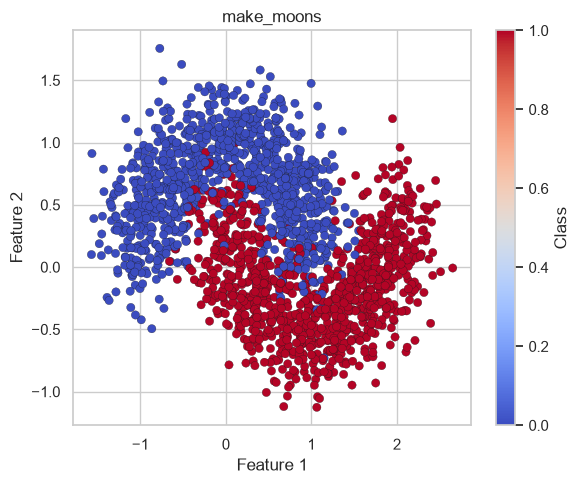

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", linewidths=0.2)
ax.set_title("make_moons")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
plt.colorbar(scatter, ax=ax, label="Class")
plt.tight_layout()
plt.show()

## Model

Regularization against overfitting: **L2 weight decay**, **dropout**, **early stopping** on validation loss.

In [5]:
def build_ann() -> keras.Model:
    return keras.Sequential(
        [
            layers.Input(shape=(2,)),
            layers.Dense(48, activation="relu", kernel_regularizer=L2),
            layers.Dropout(0.25),
            layers.Dense(24, activation="relu", kernel_regularizer=L2),
            layers.Dropout(0.25),
            layers.Dense(1, activation="sigmoid"),
        ],
        name="moons_ann",
    )


model = build_ann()
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "moons_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 48)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         1,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            25 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,345 (5.25 KB)

 Trainable params: 1,345 (5.25 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=15, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5
    ),
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.6758 - loss: 0.6275 - val_accuracy: 0.8469 - val_loss: 0.5028 - learning_rate: 0.0010
Epoch 2/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8539 - loss: 0.4373 - val_accuracy: 0.8562 - val_loss: 0.3604 - learning_rate: 0.0010
Epoch 3/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8648 - loss: 0.3526 - val_accuracy: 0.8562 - val_loss: 0.3187 - learning_rate: 0.0010
Epoch 4/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8656 - loss: 0.3266 - val_accuracy: 0.8625 - val_loss: 0.3075 - learning_rate: 0.0010
Epoch 5/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8680 - loss: 0.3267 - val_accuracy: 0.8656 - val_loss: 0.3015 - learning_rate: 0.0010
Epoch 6/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8742 - loss: 0.3100 - val_accuracy: 0.8656 - val_loss: 0.2943 - learning_rate: 0.0010
Epoch 7/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8766 - loss: 0.2985 - val_ac

In [7]:
best_epoch = int(np.argmin(history.history["val_loss"]))
train_acc = float(history.history["accuracy"][best_epoch])
val_acc = float(history.history["val_accuracy"][best_epoch])
gap = train_acc - val_acc

y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
test_acc = accuracy_score(y_test, y_pred)

print(f"Epoch with best val loss:        {best_epoch + 1}")
print(f"Train accuracy at that epoch:    {train_acc * 100:.2f}%")
print(f"Val accuracy at that epoch:      {val_acc * 100:.2f}%")
print(f"Train–val gap:                   {gap * 100:.2f} pp")
print(f"Test accuracy (held-out):        {test_acc * 100:.2f}%")
print("\n", classification_report(y_test, y_pred, target_names=["class_0", "class_1"]))

if gap > 0.08:
    print("Warning: train–val gap > 8 pp — consider more dropout or a smaller network.")
assert test_acc >= 0.85, f"Need test accuracy ≥ 85% (got {test_acc:.2%})"

Best train accuracy (any epoch): 95.16%
Best val accuracy (any epoch):   96.88%
Train–val gap:                   -1.72 pp
Test accuracy (held-out):        92.50%

               precision    recall  f1-score   support

     class_0       0.93      0.92      0.92       200
     class_1       0.92      0.94      0.93       200

    accuracy                           0.93       400
   macro avg       0.93      0.93      0.92       400
weighted avg       0.93      0.93      0.92       400



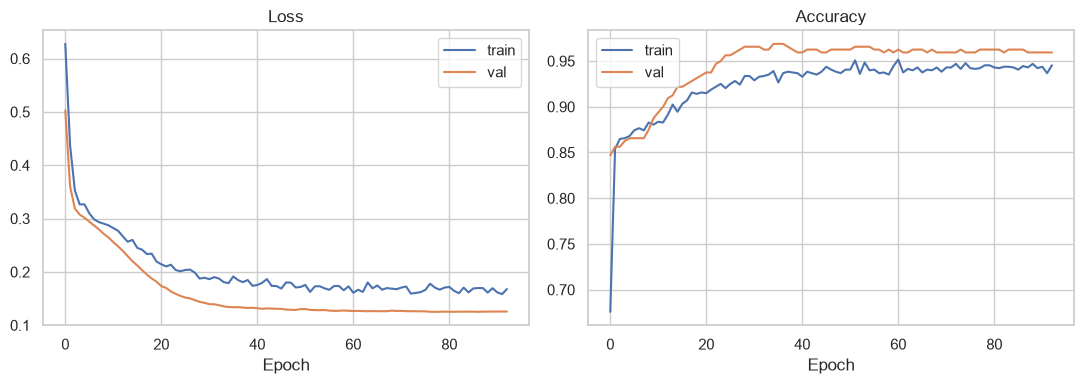

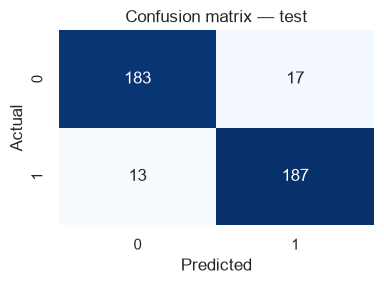

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion matrix — test")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()